# PHYS 690 - Lecture 17: Bayesian Inference on a Grid

## From a generative experiment to a posterior distribution

Lecture 15 introduced the shared Ramsey model,

$$
p_e(t\mid\boldsymbol{\theta})=\frac{1}{2}\left[1+C e^{-t/\tau}\cos(\omega t+\phi)\right],
\qquad \boldsymbol{\theta}=(C,\tau,\omega,\phi).
$$

Lecture 16 used this probability to generate excited-state counts: at delay $t_i$, the count $K_i$ from $n_i$ shots follows a binomial distribution. Here we condition on one fixed, reproducible synthetic data set of those counts. The random outcomes are now observed; we vary the unknown model parameters to ask which values plausibly produced them. This data set is generated with the same Ramsey model and parameter values as the previous lectures, using a separate seed so the observed counts are fixed for this inference example.

We infer the reduced parameter vector $\boldsymbol{\psi}=(\tau,C)$, in that order as used by the code, while holding the calibrated $\omega$ and $\phi$ fixed. Lecture 16 propagated an assumed calibration covariance for $(\tau,C)$; here we infer these parameters directly from the binomial data and a stated prior. A grid makes the likelihood, prior, and posterior visible before Lecture 18 introduces MCMC.

## Learning goals

By the end of class, you should be able to:

1. define likelihood as a function of parameters for fixed observed data;
2. distinguish likelihood, prior, posterior, and evidence;
3. normalize a posterior stably using log probabilities;
4. compute marginal distributions and confidence intervals; and
5. compare a weighted chi-square approximation with a binomial Bayesian posterior.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.special import logsumexp
from scipy.stats import binom

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

def ramsey_probability(t, contrast, tau, omega, phase):
    t = np.asarray(t)
    probability = 0.5 * (
        1.0 + contrast * np.exp(-t / tau) * np.cos(omega * t + phase)
    )
    return np.clip(probability, 1.0e-12, 1.0 - 1.0e-12)


# Bounds of the uniform prior used in the Bayesian grid calculations.
tau_prior_min = 0.4
tau_prior_max = 6.0
contrast_prior_min = 0.0
contrast_prior_max = 1.0

true_parameters = {
    "contrast": 0.78,
    "tau": 2.40,
    "omega": 2.0 * np.pi * 0.85,
    "phase": 0.25,
}

# Generate the same reproducible finite-shot data in Lectures 17-19.
data_rng = np.random.default_rng(69017)
delays = np.linspace(0.0, 5.0, 31)
shots = np.full(delays.size, 250, dtype=int)
generating_probability = ramsey_probability(delays, **true_parameters)
counts = data_rng.binomial(shots, generating_probability)

ramsey_data_df = pd.DataFrame({
    "time_us": delays,
    "shots": shots,
    "excited_counts": counts,
    "measured_probability": counts / shots,
    "generating_probability": generating_probability,
})

omega_fixed = true_parameters["omega"]
phase_fixed = true_parameters["phase"]

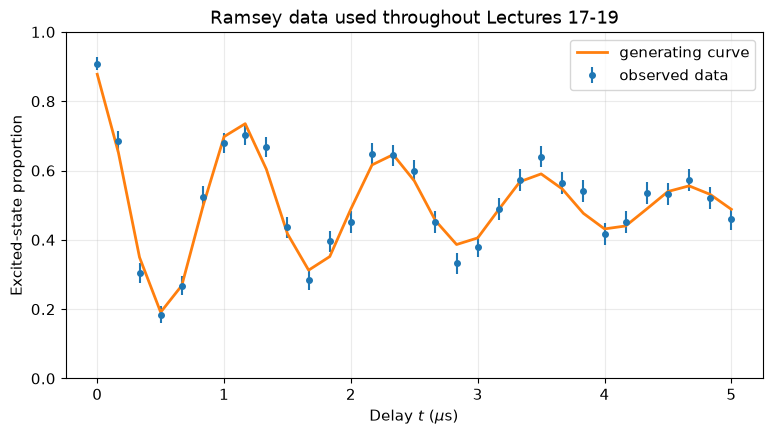

In [9]:
# Plot the fixed data before constructing the likelihood.
fig, ax = plt.subplots(figsize=(9, 4.5))
measured_se = np.sqrt(
    ramsey_data_df["measured_probability"]
    * (1.0 - ramsey_data_df["measured_probability"])
    / ramsey_data_df["shots"]
)
ax.errorbar(ramsey_data_df["time_us"], ramsey_data_df["measured_probability"],
            yerr=measured_se, fmt="o", ms=4, label="observed data")
ax.plot(ramsey_data_df["time_us"], ramsey_data_df["generating_probability"],
        lw=2, label="generating curve")
ax.set(xlabel=r"Delay $t$ ($\mu$s)", ylabel="Excited-state proportion",
       title="Ramsey data used throughout Lectures 17-19")
ax.set_ylim(0.0, 1.0)
ax.legend()
plt.show()

## Part 1: Probability of data and likelihood of parameters

Lecture 16 treated each excited count as a random variable $K_i$ with a binomial distribution. After collecting the experiment, the delay $t_i$, shot count $n_i$, and observed excited count $k_i$ are fixed. For a proposed parameter pair $\boldsymbol{\psi}=(\tau,C)$, with $\omega$ and $\phi$ held at their calibrated values, the probability of observing the count at one delay is

$$
P(K_i=k_i\mid n_i,t_i,\boldsymbol{\psi})={n_i\choose k_i}
p_i(\boldsymbol{\psi})^{k_i}[1-p_i(\boldsymbol{\psi})]^{n_i-k_i},
\qquad p_i(\boldsymbol{\psi})=p_e(t_i\mid C,\tau,\omega,\phi).
$$

Following Lecture 08, the **likelihood** is the probability of the observed data viewed as a function of the model parameters. For this fixed measurement design, write

$$
L(\boldsymbol{\psi})=P(D_{\mathrm{obs}}\mid\boldsymbol{\psi}).
$$

The observed data $D_{\mathrm{obs}}$ here are the excited counts at all measured delays; dependence on the fixed delays $t_i$ and shot counts $n_i$ is implicit. Assuming independent binomial counts at those delays, the likelihood is

$$
L(\boldsymbol{\psi})=\prod_i {n_i\choose k_i}
p_i(\boldsymbol{\psi})^{k_i}[1-p_i(\boldsymbol{\psi})]^{n_i-k_i}.
$$

This is the binomial model from Lecture 16 applied to the fixed counts in `ramsey_data_df`; it uses both the integer counts and the number of shots. It is not a Gaussian fit to the measured proportions. As in Lecture 08, $L(\boldsymbol{\psi})$ is not a probability distribution over parameters and does not need to integrate to one over parameter space.

Products of many probabilities underflow, so computation uses the log likelihood:

$$
\log L(\boldsymbol{\psi})=\sum_i\left[\log{n_i\choose k_i}
+k_i\log p_i+(n_i-k_i)\log(1-p_i)\right].
$$

The code uses SciPy's `binom.logpmf(k_i, n_i, p_i)` to evaluate each binomial log probability directly, then sums them. This is the standard binomial probability function in log form; it includes the combinatorial factor internally and avoids underflow. Taking the logarithm changes a product into a sum and has the same maximizing parameter values.

In [3]:
def binomial_log_likelihood(tau, contrast, data_df=ramsey_data_df):
    # Return -infinity outside the physical parameter region.
    if tau <= 0.0 or contrast < 0.0 or contrast > 1.0:
        return -np.inf

    probability = ramsey_probability(
        data_df["time_us"].to_numpy(), contrast, tau, omega_fixed, phase_fixed
    )
    n = data_df["shots"].to_numpy()
    k = data_df["excited_counts"].to_numpy()

    # Evaluate each observed count with the standard binomial log-PMF.
    return np.sum(binom.logpmf(k, n, probability))


def log_prior(tau, contrast):
    # Use independent uniform priors over a physically allowed teaching range.
    if (
        tau_prior_min <= tau <= tau_prior_max
        and contrast_prior_min <= contrast <= contrast_prior_max
    ):
        return -np.log(
            (tau_prior_max - tau_prior_min)
            * (contrast_prior_max - contrast_prior_min)
        )
    return -np.inf


def log_posterior(parameters):
    tau, contrast = parameters
    return log_prior(tau, contrast) + binomial_log_likelihood(tau, contrast)

## Part 2: Bayes' theorem

Bayes' theorem combines the Lecture 08 likelihood for the observed data with a prior distribution over the reduced parameter vector $\boldsymbol{\psi}=(\tau,C)$:

$$
p(\boldsymbol{\psi}\mid D_{\mathrm{obs}})=\frac{p(D_{\mathrm{obs}}\mid\boldsymbol{\psi})p(\boldsymbol{\psi})}{p(D_{\mathrm{obs}})}.
$$

- $p(D_{\mathrm{obs}}\mid\boldsymbol{\psi}) = L(\boldsymbol{\psi})$ is the likelihood from Part 1.
- $p(\boldsymbol{\psi})$ is the prior density, specified before using these counts.
- $p(\boldsymbol{\psi}\mid D_{\mathrm{obs}})$ is the posterior density.
- $p(D_{\mathrm{obs}})=\int L(\boldsymbol{\psi})p(\boldsymbol{\psi})\,d\tau\,dC$ is the evidence that normalizes the posterior.

For parameter estimation within one model, we can evaluate the unnormalized log posterior and normalize it numerically. The prior still matters: its support and parameterization express assumptions that the data may not overwhelm.

**Discuss:** Does a uniform prior mean “no assumptions”? Which assumptions are already encoded by its endpoints and parameterization?

## Part 3: Worked one-parameter posterior

First hold $C$ fixed at the calibration mean used for the $(\tau,C)$ example in Lecture 16, $C=0.78$, and infer only $\tau$. This makes the first comparison one-dimensional while preserving the same observed counts. The fixed value is a teaching simplification; the joint analysis in Part 5 allows both parameters to vary.

### Bayesian calculation first: density, grid-cell probabilities, and grid spacing

With $C$, $\omega$, and $\phi$ fixed, we evaluate the binomial likelihood and uniform prior over a grid in $\tau$. At each point, the code adds their logarithms:

$$
a_j=\log L(D_{\mathrm{obs}}\mid\tau_j)+\log p(\tau_j).
$$

Bayes' theorem requires the evidence, found by summing the unnormalized posterior over the grid. For equal spacing, $\Delta\tau$ is a common factor and cancels when we normalize:

$$
P_j\approx\frac{e^{a_j}}{\sum_k e^{a_k}}.
$$

Here, `one_d_log_posterior` stores the $a_j$ values. `logsumexp` evaluates the normalization sum stably, so subtracting it before exponentiating gives grid-cell probabilities that sum to one. These probabilities approximate the posterior probability in each cell; the continuous posterior itself is a density. With unequal spacing, each density value must be multiplied by its cell width before normalization.

The central 68% interval contains 68% of the normalized grid-cell probabilities. Grid resolution is still an approximation: repeat the calculation with half the spacing and check that the interval endpoints change negligibly. Also check that grid-cell probabilities near the boundaries are small, or the grid may truncate the posterior.

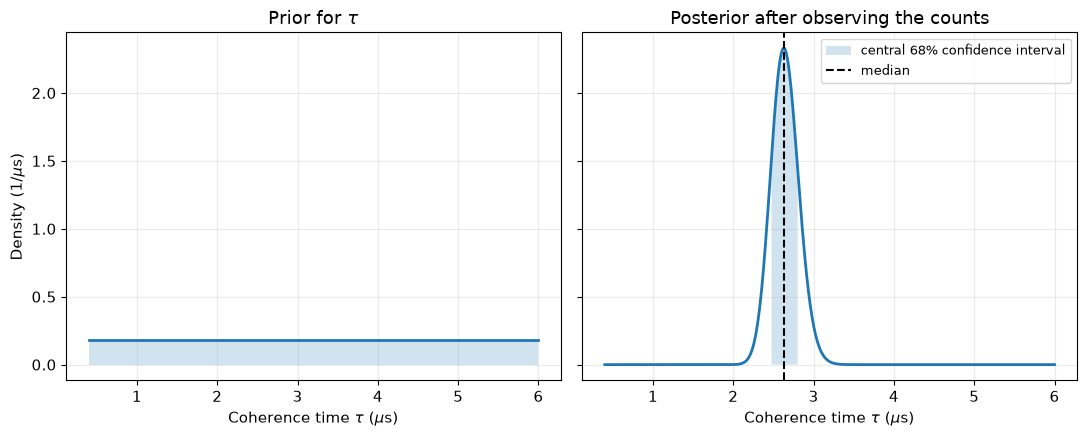

Bayesian posterior median tau = 2.633 microseconds
Bayesian central 68% confidence interval = [2.467, 2.809] microseconds


In [10]:
# Fix the calibration value shared by both analyses.
contrast_fixed = 0.78

# Define the one-parameter grid and the uniform prior used for this example.
tau_grid = np.linspace(tau_prior_min, tau_prior_max, 500)
one_d_log_prior = np.where(
    (tau_grid >= tau_prior_min) & (tau_grid <= tau_prior_max),
    -np.log(tau_prior_max - tau_prior_min), -np.inf
)
one_d_prior_df = pd.DataFrame({
    "tau": tau_grid,
    "prior_density": np.exp(one_d_log_prior),
})

# Evaluate the binomial likelihood and combine it with the prior.
one_d_log_likelihood = np.array([
    binomial_log_likelihood(tau, contrast_fixed) for tau in tau_grid
])
one_d_log_posterior = one_d_log_likelihood + one_d_log_prior

# logsumexp is the log of the discrete evidence sum; subtract it before exponentiating.
# The common grid-cell width cancels when these probabilities are normalized.
one_d_grid_probabilities = np.exp(one_d_log_posterior - logsumexp(one_d_log_posterior))
one_d_cdf = np.cumsum(one_d_grid_probabilities)
one_d_quantiles = np.interp([0.16, 0.50, 0.84], one_d_cdf, tau_grid)

# Convert the posterior grid-cell probabilities into a density for plotting on the same scale as the prior.
tau_grid_spacing = tau_grid[1] - tau_grid[0]
one_d_posterior_df = pd.DataFrame({
    "tau": tau_grid,
    "posterior_density": one_d_grid_probabilities / tau_grid_spacing,
})

# Compare the prior with the posterior after conditioning on the observed counts.
fig, (ax_prior, ax_posterior) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
ax_prior.plot(one_d_prior_df["tau"], one_d_prior_df["prior_density"], lw=2)
ax_prior.fill_between(
    one_d_prior_df["tau"], 0.0, one_d_prior_df["prior_density"], alpha=0.2
)
ax_prior.set(
    xlabel=r"Coherence time $\tau$ ($\mu$s)",
    ylabel=r"Density (1/$\mu$s)",
    title=r"Prior for $\tau$",
)

ax_posterior.plot(
    one_d_posterior_df["tau"], one_d_posterior_df["posterior_density"], lw=2
)
in_confidence_interval = one_d_posterior_df["tau"].between(
    one_d_quantiles[0], one_d_quantiles[2]
)
ax_posterior.fill_between(
    one_d_posterior_df.loc[in_confidence_interval, "tau"],
    0.0,
    one_d_posterior_df.loc[in_confidence_interval, "posterior_density"],
    alpha=0.2,
    label="central 68% confidence interval",
)
ax_posterior.axvline(one_d_quantiles[1], color="black", ls="--", label="median")
ax_posterior.set(
    xlabel=r"Coherence time $\tau$ ($\mu$s)",
    title="Posterior after observing the counts",
)
ax_posterior.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"Bayesian posterior median tau = {one_d_quantiles[1]:.3f} microseconds")
print(
    "Bayesian central 68% confidence interval = "
    f"[{one_d_quantiles[0]:.3f}, {one_d_quantiles[2]:.3f}] microseconds"
)

### Comparison with a weighted $\chi^2$ fit from Unit 2

A familiar approach is to fit the measured proportions $\widehat p_i=k_i/n_i$ with the Ramsey curve, keeping $C=0.78$, $\omega$, and $\phi$ fixed as above. Lecture 16 gives the binomial standard deviation of a measured proportion. Since the true $p_i$ is unknown in real data, estimate it here with the observed proportion:

$$
\widehat\sigma_i\approx\sqrt{\frac{\widehat p_i(1-\widehat p_i)}{n_i}}.
$$

Then `curve_fit` minimizes the weighted chi-square. With these uncertainties treated as fixed, minimizing $\chi^2$ is equivalent to maximizing a Gaussian likelihood:

$$
\chi^2(\tau)=\sum_i\frac{[\widehat p_i-p_e(t_i\mid C=0.78,\tau,\omega,\phi)]^2}{\widehat\sigma_i^2},
$$

This is the usual Gaussian-error approximation to the binomial measurements. It assumes independent measured proportions that are approximately Gaussian and treats the estimated $\widehat\sigma_i$ values as known weights. With 250 shots per delay and probabilities away from zero and one, this is a reasonable teaching comparison, though the uncertainty estimates are themselves data-based. We use `absolute_sigma=True` so the returned `pcov` is scaled to these supplied uncertainties; $\sqrt{\mathrm{pcov}_{\tau\tau}}$ gives a local, approximately symmetric one-standard-deviation error. This interval relies on the likelihood being locally quadratic near its minimum.

In [11]:
def probability_at_fixed_calibration(time_us, tau):
    # curve_fit varies only tau; C, omega, and phase remain fixed.
    return ramsey_probability(
        time_us, contrast_fixed, tau, omega_fixed, phase_fixed
    )

# Use the observed proportions to estimate their binomial standard errors.
observed_proportion = ramsey_data_df["measured_probability"].to_numpy()
shot_count = ramsey_data_df["shots"].to_numpy()
proportion_standard_error = np.sqrt(
    observed_proportion * (1.0 - observed_proportion) / shot_count
)

# Fit tau by weighted least squares, with the same physical range used by the grid.
chi2_fit_parameters, chi2_fit_pcov = curve_fit(
    probability_at_fixed_calibration,
    ramsey_data_df["time_us"].to_numpy(),
    observed_proportion,
    p0=[2.4],
    sigma=proportion_standard_error,
    absolute_sigma=True,
    bounds=([tau_prior_min], [tau_prior_max]),
)
tau_chi2_fit = chi2_fit_parameters[0]
tau_chi2_standard_error = np.sqrt(chi2_fit_pcov[0, 0])

# Calculate the minimized chi-square and its degrees of freedom for context.
chi2_residuals = (
    observed_proportion
    - probability_at_fixed_calibration(
        ramsey_data_df["time_us"].to_numpy(), tau_chi2_fit
    )
) / proportion_standard_error
chi2_minimum = np.sum(chi2_residuals**2)
chi2_degrees_of_freedom = len(observed_proportion) - len(chi2_fit_parameters)

chi2_fit_summary_df = pd.DataFrame({
    "quantity": ["tau fit (microseconds)", "one-standard-deviation uncertainty (microseconds)",
                 "chi-square", "degrees of freedom"],
    "value": [tau_chi2_fit, tau_chi2_standard_error,
              chi2_minimum, chi2_degrees_of_freedom],
})
display(chi2_fit_summary_df)

,quantity,value
0,tau fit (microseconds),2.654024
1,one-standard-deviation uncertainty (microseconds),0.171534
2,chi-square,32.712274
3,degrees of freedom,30.000000


### Compare the estimates and uncertainty statements

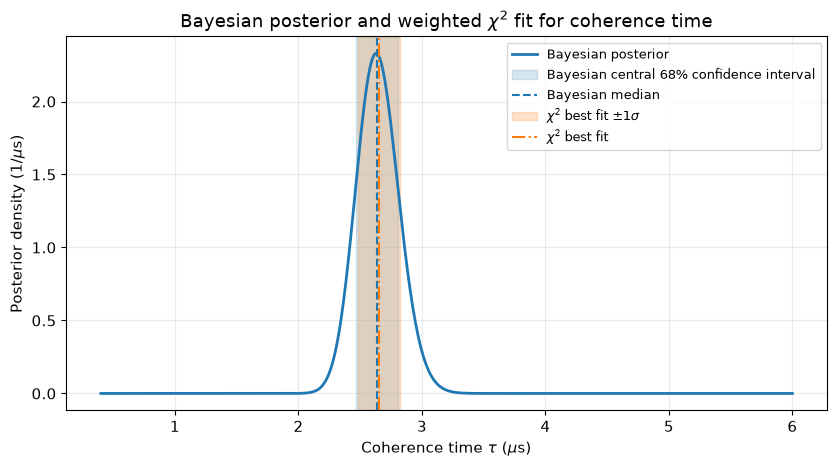

,method,central tau (microseconds),lower interval (microseconds),upper interval (microseconds),chi-square / dof,interval interpretation
0,weighted chi-square (`curve_fit`),2.654024,2.482489,2.825558,32.71 / 30,local approximate 1-sigma
1,binomial Bayesian grid,2.633181,2.467298,2.808668,not used,central 68% posterior confidence


In [12]:
# Convert the grid-cell probabilities to a density for plotting against tau.
tau_grid_spacing = tau_grid[1] - tau_grid[0]
one_d_posterior_density = one_d_grid_probabilities / tau_grid_spacing

# Display the Bayesian interval and the chi-square fit uncertainty on the same axis.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(tau_grid, one_d_posterior_density, color="tab:blue", lw=2,
        label="Bayesian posterior")
ax.axvspan(one_d_quantiles[0], one_d_quantiles[2], color="tab:blue", alpha=0.18,
          label="Bayesian central 68% confidence interval")
ax.axvline(one_d_quantiles[1], color="tab:blue", ls="--",
           label="Bayesian median")
ax.axvspan(tau_chi2_fit - tau_chi2_standard_error,
           tau_chi2_fit + tau_chi2_standard_error,
           color="tab:orange", alpha=0.22,
           label=r"$\chi^2$ best fit $\pm 1\sigma$")
ax.axvline(tau_chi2_fit, color="tab:orange", ls="-.",
           label=r"$\chi^2$ best fit")
ax.set(
    xlabel=r"Coherence time $\tau$ ($\mu$s)",
    ylabel=r"Posterior density (1/$\mu$s)",
    title="Bayesian posterior and weighted $\\chi^2$ fit for coherence time",
)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# Put both estimates and interval endpoints side by side for a numerical comparison.
tau_comparison_df = pd.DataFrame({
    "method": ["weighted chi-square (`curve_fit`)", "binomial Bayesian grid"],
    "central tau (microseconds)": [tau_chi2_fit, one_d_quantiles[1]],
    "lower interval (microseconds)": [
        tau_chi2_fit - tau_chi2_standard_error, one_d_quantiles[0]
    ],
    "upper interval (microseconds)": [
        tau_chi2_fit + tau_chi2_standard_error, one_d_quantiles[2]
    ],
    "chi-square / dof": [
        f"{chi2_minimum:.2f} / {chi2_degrees_of_freedom}", "not used"
    ],
    "interval interpretation": [
        "local approximate 1-sigma", "central 68% posterior confidence"
    ],
})
display(tau_comparison_df)

The Bayesian interval contains 68% of the posterior probability under the stated binomial model and uniform prior. It is conditional on the observed counts and assumptions. The `curve_fit` interval, by contrast, is a local one-standard-deviation estimate from the curvature of weighted $\chi^2$ near its minimum. It is approximately symmetric and relies on the Gaussian-error approximation; for one fitted parameter near a regular minimum, it corresponds approximately to $\Delta\chi^2=1$.

The Bayesian calculation uses the binomial probability of the integer counts and normalizes over the stated range $0.4\leq\tau\leq6.0$. It can show asymmetry, boundary effects, and the influence of a prior explicitly. When the counts are large, the estimate is far from parameter limits, and the posterior is close to Gaussian, the methods should give similar results. Bayesian inference is useful when those approximations are questionable or when prior information needs to be included transparently.

## Part 4: In-class coding activity 1 - Normalize and summarize a posterior

Use the same one-parameter binomial likelihood and observed counts as in Part 3. Repeat the calculation on a broader $\tau$ grid, but replace the uniform prior with a Gaussian prior centered at $2.5~\mu s$ with standard deviation $0.8~\mu s$. This is a deliberately chosen prior for practicing prior sensitivity; it is not the calibration distribution from Lecture 16. Normalize in log space and compute the central 68% confidence interval.

In [ ]:
activity_tau_grid = np.linspace(0.2, 8.0, 600)
activity_log_likelihood = np.array([
    binomial_log_likelihood(tau, contrast_fixed) for tau in activity_tau_grid
])

# Ignore the additive Gaussian normalization because the grid will be normalized below.
activity_log_prior = -0.5 * ((activity_tau_grid - 2.5) / 0.8)**2

# TODO: Add log likelihood and log prior.
activity_log_posterior = activity_log_prior + activity_log_likelihood
# TODO: Convert to stably normalized discrete posterior weights.
activity_grid_probabilities = np.exp(activity_log_posterior - logsumexp(activity_log_posterior))
# TODO: Build the cumulative distribution and interpolate its 16%, 50%, and 84% quantiles.
activity_cdf = np.cumsum(activity_grid_probabilities) / activity_grid_probabilities.sum()
activity_quantiles = np.interp([0.16, 0.50, 0.84], activity_cdf, activity_tau_grid)

print("Gaussian-prior posterior quantiles:", activity_quantiles)
print("Discrete normalization:", activity_grid_probabilities.sum())
print("")

print(f"Bayesian posterior median tau = {activity_quantiles[1]:.3f} microseconds")
print(
    "Bayesian central 68% confidence interval = "
    f"[{activity_quantiles[0]:.3f}, {activity_quantiles[2]:.3f}] microseconds"
)

## Part 5: A two-parameter posterior and marginalization

Now infer $\tau$ and $C$ jointly using the same fixed counts and binomial likelihood. A lower contrast and faster decay can both reduce late-time oscillation amplitude, so the joint posterior can show parameter dependence.

This covariance is related to the $(\tau,C)$ calibration covariance discussed in Lecture 16, but it has a different origin: Lecture 16 began with an assumed calibration `pcov` and propagated it through the model; here, the posterior grid and observed counts determine the parameter covariance. A nuisance parameter is not removed by fixing it at its best value. Bayesian marginalization integrates over its posterior uncertainty:

$$
p(\tau\mid D_{\mathrm{obs}})=\int p(\tau,C\mid D_{\mathrm{obs}})\,dC.
$$

On this equally spaced grid, the integral is approximated by summing normalized joint grid-cell probabilities along the nuisance-parameter axis.

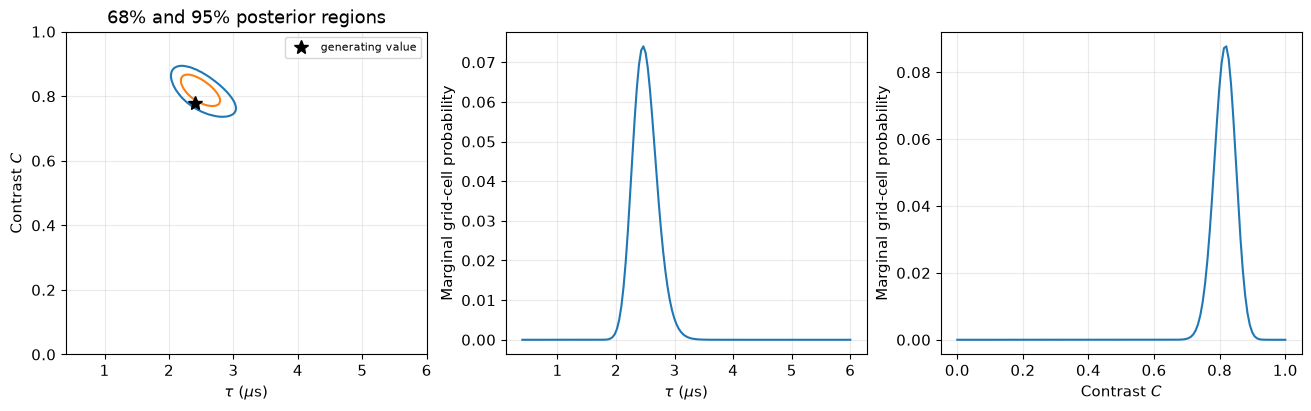

In [24]:
tau_grid_2d = np.linspace(tau_prior_min, tau_prior_max, 150)
contrast_grid_2d = np.linspace(contrast_prior_min, contrast_prior_max, 140)
log_posterior_grid = np.empty((contrast_grid_2d.size, tau_grid_2d.size))

# Evaluate the posterior at every grid point.
for contrast_index, contrast in enumerate(contrast_grid_2d):
    for tau_index, tau in enumerate(tau_grid_2d):
        log_posterior_grid[contrast_index, tau_index] = log_posterior([tau, contrast])

posterior_grid = np.exp(log_posterior_grid - logsumexp(log_posterior_grid))
tau_marginal = posterior_grid.sum(axis=0)
contrast_marginal = posterior_grid.sum(axis=1)

# Store the joint and marginal probabilities in labeled DataFrames for plotting.
posterior_grid_df = pd.DataFrame(
    posterior_grid, index=contrast_grid_2d, columns=tau_grid_2d
)
tau_marginal_df = pd.DataFrame({"tau": tau_grid_2d, "grid_cell_probability": tau_marginal})
contrast_marginal_df = pd.DataFrame({
    "contrast": contrast_grid_2d, "grid_cell_probability": contrast_marginal
})

# Convert highest-density thresholds to enclosed probability levels.
sorted_grid_cell_probabilities = np.sort(posterior_grid.ravel())[::-1]
enclosed_probability = np.cumsum(sorted_grid_cell_probabilities)
contour_68 = sorted_grid_cell_probabilities[np.searchsorted(enclosed_probability, 0.68)]
contour_95 = sorted_grid_cell_probabilities[np.searchsorted(enclosed_probability, 0.95)]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
axes[0].contour(posterior_grid_df.columns.to_numpy(),
                posterior_grid_df.index.to_numpy(), posterior_grid_df.to_numpy(),
                levels=[contour_95, contour_68], colors=["tab:blue", "tab:orange"])
axes[0].plot(true_parameters["tau"], true_parameters["contrast"], "k*", ms=10,
             label="generating value")
axes[0].set(xlabel=r"$\tau$ ($\mu$s)", ylabel=r"Contrast $C$",
            title="68% and 95% posterior regions")
axes[0].legend(fontsize=8)
axes[1].plot(tau_marginal_df["tau"], tau_marginal_df["grid_cell_probability"])
axes[1].set(xlabel=r"$\tau$ ($\mu$s)", ylabel="Marginal grid-cell probability")
axes[2].plot(contrast_marginal_df["contrast"], contrast_marginal_df["grid_cell_probability"])
axes[2].set(xlabel=r"Contrast $C$", ylabel="Marginal grid-cell probability")
plt.show()

### In-class coding activity 2 - Quantify posterior dependence

Treat the normalized grid as a discrete joint distribution. Calculate posterior means, covariance, and correlation for $(\tau,C)$. Compare the sign and orientation of this posterior dependence with Lecture 16's calibration-draw plot, then explain why the numerical covariance need not equal Lecture 16's assumed `pcov`. Summarize each marginal with its central 68% confidence interval.

For joint grid-cell probabilities $P_{jk}$, the covariance is

$$
\mathrm{Cov}(\tau,C)=\sum_{j,k}P_{jk}(\tau_j-\bar{\tau})(C_k-\bar{C}).
$$

The two deviations are multiplied, not squared. Their product can be negative when larger values of one parameter tend to occur with smaller values of the other. Squaring a single parameter's deviation instead gives its variance, which is used in the denominator when converting covariance to correlation. The squared residuals in a $\chi^2$ fit serve a different purpose: they measure mismatch between data and a model.

In [ ]:
tau_mesh, contrast_mesh = np.meshgrid(tau_grid_2d, contrast_grid_2d)

# TODO: Calculate the posterior means of tau and contrast.
posterior_mean_tau = np.sum(tau_mesh * posterior_grid)
# TODO: Calculate the posterior mean of contrast.
posterior_mean_contrast = np.sum(contrast_mesh * posterior_grid)
# Covariance uses the product of centered tau and contrast deviations; do not square them.
posterior_covariance = np.sum((tau_mesh - posterior_mean_tau) * (contrast_mesh - posterior_mean_contrast) * posterior_grid)
# TODO: Calculate both variances and convert covariance to correlation.
posterior_correlation = posterior_covariance / np.sqrt(
    np.sum((tau_mesh - posterior_mean_tau)**2 * posterior_grid)
    * np.sum((contrast_mesh - posterior_mean_contrast)**2 * posterior_grid)
)

# TODO: Compute central 68% quantiles from both marginal CDFs.
tau_quantiles_2d = np.interp([0.16, 0.50, 0.84], np.cumsum(tau_marginal) / tau_marginal.sum(), tau_grid_2d)
# TODO: Compute the corresponding contrast quantiles.
contrast_quantiles_2d = np.interp([0.16, 0.50, 0.84], np.cumsum(contrast_marginal) / contrast_marginal.sum(), contrast_grid_2d)

joint_summary_df = pd.DataFrame({
    "quantity": ["mean", "16%", "50%", "84%"],
    "tau": [posterior_mean_tau, *tau_quantiles_2d],
    "contrast": [posterior_mean_contrast, *contrast_quantiles_2d],
})
display(joint_summary_df)
print(f"Posterior correlation = {posterior_correlation:.3f}")

### Prior parameterization and identifiability

A prior that is uniform in $\tau$ is not uniform in the decay rate $\gamma=1/\tau$ because densities transform with a Jacobian. State the parameterization in which a prior is defined. The joint posterior also reveals identifiability: a long narrow ridge means many $(\tau,C)$ combinations explain the observed counts similarly. New measurements at informative delays or an independent calibration are needed to reduce that physical degeneracy.

## Script and HPC extension: compare grid resolution

The notebook grid is small enough for interactive work. You can also run the same calculation from a terminal with the command-line script [`scripts/lecture17/grid_posterior.py`](../scripts/lecture17/grid_posterior.py). This example saves the posterior grid to an NPZ file:

```bash
mkdir -p outputs
python -u scripts/lecture17/grid_posterior.py \
  --tau-points 150 --contrast-points 140 \
  --prior broad --seed 69017 \
  --output outputs/posterior_150x140.npz
```

### Try a finer grid on the W&M HPC cluster

Lecture 09 introduced the W&M SciClone workflow: connect to `bora.sciclone.wm.edu`, initialize the cluster shell, activate the repository's `.venv`, submit batch work with Slurm, and monitor it with `squeue`. Review [Lecture 09](lecture09_9_24_26_wm_hpc.ipynb) and the [course HPC resource guide](../resources/wmhpc.md) for account access, environment setup, and cluster guidance. Do not run long calculations directly on a shared login node.

The batch script [`scripts/lecture17/run_grid.slurm`](../scripts/lecture17/run_grid.slurm) requests one CPU and 2 GB of memory, activates the course environment, and runs the grid script. From the repository root on SciClone, first initialize the environment and make the output directories:

```bash
source /usr/local/etc/sciclone.bashrc
which sbatch
source .venv/bin/activate
mkdir -p slurm_logs outputs
```

Submit two increasingly fine grids. Both jobs use seed `69017`, so they analyze the same synthetic counts and differ only in grid resolution:

```bash
sbatch scripts/lecture17/run_grid.slurm 300 280 posterior_300x280
sbatch scripts/lecture17/run_grid.slurm 600 560 posterior_600x560
```

Check job status and inspect the results after the jobs finish:

```bash
squeue -u "$USER"
ls -lh slurm_logs outputs/posterior_*.npz
```

Compare the two posterior grids and summaries. If the confidence intervals or posterior contours change noticeably as the grid is refined, increase the resolution again. The grid makes this discretization check direct, while the rapidly growing number of grid points motivates the MCMC methods in Lecture 18.

## Connection to Monte Carlo: sampling the posterior

Lecture 15 used Monte Carlo averages to estimate integrals when evaluating a dense grid becomes expensive. Bayesian summaries are also integrals: for example, a posterior mean averages a parameter or prediction over the posterior distribution. In this lecture, the two-dimensional grid makes that distribution visible and lets us approximate those integrals by summing grid-cell probabilities.

As the number of unknown parameters grows, a grid with even a modest number of points per parameter becomes impractical. Markov chain Monte Carlo (MCMC) addresses this by generating parameter samples whose long-run distribution follows the posterior. Posterior averages and intervals can then be estimated from those samples, much like Monte Carlo estimates in Lecture 15. The important difference is what is being sampled: Lecture 15 sampled inputs to an integral, while MCMC samples parameter values from a posterior conditioned on observed data. MCMC samples are correlated, so Lecture 18 will introduce the Metropolis-Hastings algorithm and diagnostics needed to judge their reliability.

## Synthesis

- Lecture 15 supplied the Ramsey probability model; Lecture 16 showed how binomial shot counts are generated from it.
- The binomial likelihood evaluates the probability of the fixed observed counts for each proposed $(\tau,C)$ pair.
- A posterior combines that likelihood with an explicitly stated prior and must be normalized.
- Log probabilities prevent numerical underflow.
- Marginalization propagates nuisance-parameter uncertainty rather than fixing nuisance parameters.
- Posterior covariance describes dependence inferred from the data and prior; Lecture 16's `pcov` described an assumed calibration distribution.
- Confidence intervals describe posterior probability under the model and prior.
- Grid inference is transparent but its cost grows exponentially with dimension; Lecture 18 replaces the grid with MCMC samples.

## References and further reading

- [Unit 4 course resources](../resources/unit-4-monte-carlo-inference.md)
- [Allen Downey, *Think Bayes 2*](https://allendowney.github.io/ThinkBayes2/)
- [Bayes Rules! open textbook](https://www.bayesrulesbook.com/)
- [SciPy binomial distribution documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html)
- [Hogg, Bovy, and Lang, *Data analysis recipes: Fitting a model to data*](https://arxiv.org/abs/1008.4686)